# Manifold learning on handwritten digits: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/manifold/plot_lle_digits.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/manifold/plot_lle_digits.html)).

**Scenario:** the bundled digits dataset (`load_digits(n_class=6)`, 1083 × 64, no download) is
embedded in two dimensions by fifteen techniques. Moxie's manifold family implements
`ClassicalMDS` and `trustworthiness`; this notebook reproduces the *Classical MDS embedding*
panel natively and checks every other manifold estimator of the example fails clearly.

**Adaptations:**
- The reference loop runs all fifteen embeddings exactly as in the gallery. The plots are reduced
  to the Classical MDS panel (with the gallery's `plot_embedding`) plus a compact scatter grid of
  every embedding, to keep the committed notebook small (dpi ≤ 80).
- Non-manifold embeddings (random projection, truncated SVD, LDA, random trees, NCA) belong to
  other families and are verified there; they are not re-run in Mojo here.
- Extra checks beyond the gallery: `trustworthiness` of the embedding (not in this example, but the
  manifold diagnostic), Float32, other metrics, `precomputed` input, clone and refit on a 200-sample
  subset (the Float64 full-size fit takes about 3 minutes in Moxie).

**Determinism:** Classical MDS is an exact eigendecomposition with `svd_flip` sign fixing, so the
reference is deterministic and numerical parity is required. Trustworthiness depends only on
neighbor ranks; digits pixels are small integers, so ties are present (see the comparison section).


In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("manifold/plot_lle_digits")

## 1. scikit-learn (official example)

Load the digits and draw the sample grid.

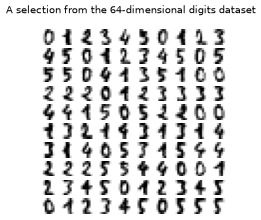

In [2]:
from sklearn.datasets import load_digits

digits = load_digits(n_class=6)
X, y = digits.data, digits.target
n_samples, n_features = X.shape
n_neighbors = 30

import matplotlib.pyplot as plt

fig, axs = plt.subplots(nrows=10, ncols=10, figsize=(4, 4), dpi=60)
for idx, ax in enumerate(axs.ravel()):
    ax.imshow(X[idx].reshape((8, 8)), cmap=plt.cm.binary)
    ax.axis("off")
_ = fig.suptitle("A selection from the 64-dimensional digits dataset", fontsize=12)

In [3]:
import numpy as np
from matplotlib import offsetbox

from sklearn.preprocessing import MinMaxScaler


def plot_embedding(X, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 5), dpi=70)
    X = MinMaxScaler().fit_transform(X)
    for digit in digits.target_names:
        ax.scatter(
            *X[y == digit].T,
            marker=f"${digit}$",
            s=60,
            color=plt.cm.Dark2(digit),
            alpha=0.425,
            zorder=2,
        )
    shown_images = np.array([[1.0, 1.0]])  # just something big
    for i in range(X.shape[0]):
        # plot every digit on the embedding
        # show an annotation box for a group of digits
        dist = np.sum((X[i] - shown_images) ** 2, 1)
        if np.min(dist) < 4e-3:
            # don't show points that are too close
            continue
        shown_images = np.concatenate([shown_images, [X[i]]], axis=0)
        imagebox = offsetbox.AnnotationBbox(
            offsetbox.OffsetImage(digits.images[i], cmap=plt.cm.gray_r), X[i]
        )
        imagebox.set(zorder=1)
        ax.add_artist(imagebox)

    ax.set_title(title)
    ax.axis("off")

In [4]:
from sklearn.decomposition import TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomTreesEmbedding
from sklearn.manifold import (
    MDS,
    TSNE,
    ClassicalMDS,
    Isomap,
    LocallyLinearEmbedding,
    SpectralEmbedding,
)
from sklearn.neighbors import NeighborhoodComponentsAnalysis
from sklearn.pipeline import make_pipeline
from sklearn.random_projection import SparseRandomProjection

embeddings = {
    "Random projection embedding": SparseRandomProjection(
        n_components=2, random_state=42
    ),
    "Truncated SVD embedding": TruncatedSVD(n_components=2),
    "Linear Discriminant Analysis embedding": LinearDiscriminantAnalysis(
        n_components=2
    ),
    "Isomap embedding": Isomap(n_neighbors=n_neighbors, n_components=2),
    "Standard LLE embedding": LocallyLinearEmbedding(
        n_neighbors=n_neighbors, n_components=2, method="standard"
    ),
    "Modified LLE embedding": LocallyLinearEmbedding(
        n_neighbors=n_neighbors, n_components=2, method="modified"
    ),
    "Hessian LLE embedding": LocallyLinearEmbedding(
        n_neighbors=n_neighbors, n_components=2, method="hessian"
    ),
    "LTSA LLE embedding": LocallyLinearEmbedding(
        n_neighbors=n_neighbors, n_components=2, method="ltsa"
    ),
    "Metric MDS embedding": MDS(n_components=2, n_init=1, init="classical_mds"),
    "Non-metric MDS embedding": MDS(
        n_components=2, n_init=1, init="classical_mds", metric_mds=False
    ),
    "Classical MDS embedding": ClassicalMDS(n_components=2),
    "Random Trees embedding": make_pipeline(
        RandomTreesEmbedding(n_estimators=200, max_depth=5, random_state=0),
        TruncatedSVD(n_components=2),
    ),
    "Spectral embedding": SpectralEmbedding(
        n_components=2, random_state=0, eigen_solver="arpack"
    ),
    "t-SNE embedding": TSNE(
        n_components=2,
        max_iter=500,
        n_iter_without_progress=150,
        n_jobs=2,
        random_state=0,
    ),
    "NCA embedding": NeighborhoodComponentsAnalysis(
        n_components=2, init="pca", random_state=0
    ),
}

In [5]:
from time import time

projections, timing = {}, {}
for name, transformer in embeddings.items():
    if name.startswith("Linear Discriminant Analysis"):
        data = X.copy()
        data.flat[:: X.shape[1] + 1] += 0.01  # Make X invertible
    else:
        data = X

    print(f"Computing {name}...")
    start_time = time()
    projections[name] = transformer.fit_transform(data, y)
    timing[name] = time() - start_time

Computing Random projection embedding...
Computing Truncated SVD embedding...
Computing Linear Discriminant Analysis embedding...
Computing Isomap embedding...


Computing Standard LLE embedding...
Computing Modified LLE embedding...


Computing Hessian LLE embedding...


Computing LTSA LLE embedding...


Computing Metric MDS embedding...


Computing Non-metric MDS embedding...


Computing Classical MDS embedding...
Computing Random Trees embedding...


Computing Spectral embedding...
Computing t-SNE embedding...


Computing NCA embedding...


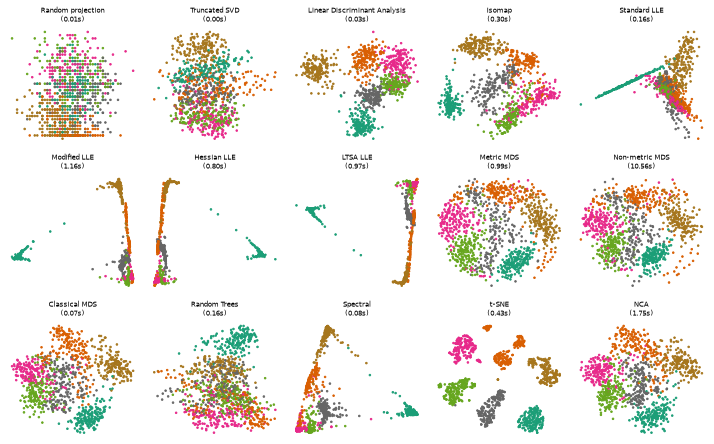

In [6]:
# The gallery draws one plot_embedding figure per method; a compact grid keeps the notebook small.
fig, axs = plt.subplots(3, 5, figsize=(12, 7.5), dpi=60)
for ax, name in zip(axs.ravel(), timing):
    P = MinMaxScaler().fit_transform(projections[name])
    ax.scatter(*P.T, c=y, cmap="Dark2", s=4)
    ax.set_title(f"{name.replace(' embedding', '')}\n({timing[name]:.2f}s)", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

Reference values for the Moxie comparison: the Classical MDS attributes, `trustworthiness` of
that embedding, and Float32 / metric / `precomputed` / clone variants on the first 200 samples.

In [7]:
from sklearn.manifold import trustworthiness
from sklearn.metrics import pairwise_distances
from sklearn.base import clone

cmds = embeddings["Classical MDS embedding"]
sk_embedding = projections["Classical MDS embedding"]
sk_trust = trustworthiness(X, sk_embedding, n_neighbors=5)
sk_trust_all = {name: trustworthiness(X, P, n_neighbors=5) for name, P in projections.items()}
print(f"sklearn trustworthiness(X, Classical MDS, n_neighbors=5) = {sk_trust:.6f}")

S = X[:200]
sk_sub = {}
sk_sub["f32"] = ClassicalMDS(n_components=2).fit_transform(S.astype(np.float32))
for metric in ["manhattan", "cosine", "chebyshev"]:
    sk_sub[metric] = ClassicalMDS(n_components=3, metric=metric).fit_transform(S)
sk_sub["minkowski_p3"] = ClassicalMDS(metric="minkowski", metric_params={"p": 3}).fit_transform(S)
D = pairwise_distances(S)
sk_sub["precomputed"] = ClassicalMDS(metric="precomputed").fit_transform(D)
refit = clone(cmds).set_params(n_components=1)
sk_sub["clone_refit"] = refit.fit_transform(S)
sk_sub["trust_k10"] = trustworthiness(S, sk_sub["f32"], n_neighbors=10)
sk_sub["trust_cosine"] = trustworthiness(S, sk_sub["cosine"], n_neighbors=7, metric="cosine")
nb.share(X=X, S=S, S32=S.astype(np.float32), D=D, sk_embedding=sk_embedding)

sklearn trustworthiness(X, Classical MDS, n_neighbors=5) = 0.867457


## 2. Moxie (native Mojo)

The full-size Float64 Classical MDS: dense dissimilarities, double centering and the decomposition
family's `symmetric_eigh`. `trustworthiness` runs on Moxie's own embedding and on the sklearn
embedding, so ranking can be compared independently of the eigensolver.

In [8]:
%%mojo classical_mds_digits
from moxie.manifold import ClassicalMDS, trustworthiness
from moxie_nb_io import load, save, save_floats, save_ints


def main() raises:
    var X = load("X")
    var model = ClassicalMDS(n_components=2)
    var embedding = model.fit_transform(X)
    save("embedding", embedding)
    save("embedding_attr", model.embedding_.value())
    save("eigenvalues", model.eigenvalues_.value())
    save("dissimilarity", model.dissimilarity_matrix_.value())
    save_ints("n_features_in", [model.n_features_in_])
    save_floats("trust", [trustworthiness(X, embedding, n_neighbors=5)])
    save_floats("trust_sk_embedding", [trustworthiness(X, load("sk_embedding"), n_neighbors=5)])
    print("eigenvalues_:", model.eigenvalues_.value())

eigenvalues_: [253773.3576 217195.3702]
1D-array  Shape: (2)  Strides: (1)  DType: f64  order: C  own data: True


In [9]:
%%mojo classical_mds_variants
from std.math import inf
from moxie.base import clone
from moxie.manifold import ClassicalMDS, trustworthiness
from moxie_nb_io import load, save, save_floats


def main() raises:
    var S = load("S")
    var f32 = ClassicalMDS[DType.float32](n_components=2)
    var e32 = f32.fit_transform(load[DType.float32]("S32"))
    save("f32", e32)
    for metric in ["manhattan", "cosine", "chebyshev"]:
        var m = ClassicalMDS(n_components=3, metric=metric)
        save(metric, m.fit_transform(S))
    var options = Dict[String, Float64]()
    options["p"] = 3
    var minkowski = ClassicalMDS(metric="minkowski", metric_params=options^)
    save("minkowski_p3", minkowski.fit_transform(S))
    var pre = ClassicalMDS(metric="precomputed")
    save("precomputed", pre.fit_transform(load("D")))
    var base = ClassicalMDS(n_components=2)
    _ = base.fit(S)
    var refit = clone(base)
    _ = refit.set_params(n_components=1)
    save("clone_refit", refit.fit_transform(S))
    save_floats("unfitted_clone", [Float64(Int(clone(base).__sklearn_is_fitted__()))])
    save_floats("trust_k10", [trustworthiness(S, e32, n_neighbors=10)])
    var cosine = ClassicalMDS(n_components=3, metric="cosine")
    save_floats("trust_cosine", [trustworthiness(S, cosine.fit_transform(S), n_neighbors=7, metric="cosine")])

## 3. Side by side and parity

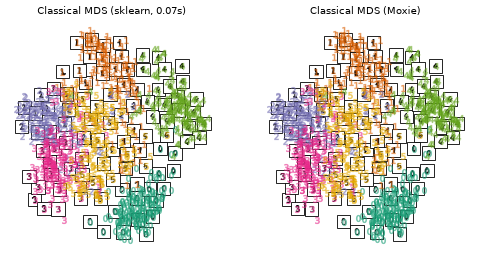

True

In [10]:
mx = nb.results["classical_mds_digits"]
moxie_nb.side_by_side(sklearn=sk_embedding[:5], moxie=mx["embedding"][:5])
fig, axs = plt.subplots(1, 2, figsize=(10, 5), dpi=60)
plot_embedding(sk_embedding, f"Classical MDS (sklearn, {timing['Classical MDS embedding']:.2f}s)", axs[0])
plot_embedding(mx["embedding"], "Classical MDS (Moxie)", axs[1])
plt.show()

EIG = ("Float64 Jacobi eigensolver (Moxie) vs LAPACK syevr (sklearn) on a 1083x1083 Gram matrix with "
       "entries ~1e3 and well-separated leading eigenvalues (2.5e5, 2.2e5); rounding only")
nb.compare("eigenvalues_", cmds.eigenvalues_, mx["eigenvalues"], rtol=1e-10, reason=EIG)
nb.compare("fit_transform / embedding_", sk_embedding, mx["embedding"], rtol=1e-8, atol=1e-8,
           reason=EIG + "; same svd_flip sign rule; coordinates ~10, so atol 1e-8 is 1e-9 relative")
nb.compare("embedding_ attribute equals returned array", mx["embedding"], mx["embedding_attr"], exact=True)
nb.compare("dissimilarity_matrix_", cmds.dissimilarity_matrix_, mx["dissimilarity"], rtol=1e-12, atol=1e-12,
           reason="sklearn euclidean_distances uses the |x|^2-2xy+|y|^2 expansion, Moxie the direct difference; "
                  "integer pixels keep both within a few ulps")
nb.compare("n_features_in_", cmds.n_features_in_, mx["n_features_in"][0], exact=True)

**Trustworthiness and ties.** Digits pixels are integers in 0–16, so many pairwise distances
tie exactly. sklearn ranks the original space with `np.argsort` (unstable quicksort) and the embedded
space with `NearestNeighbors`; Moxie breaks every tie by increasing sample index (documented in
`families/manifold/docs/algorithms.md`). The score on Moxie's own embedding is therefore compared
with a stable-tie reference computed below, and with sklearn's value within the tie-induced
spread measured on the same inputs.

In [11]:
def stable_trustworthiness(X, E, k, metric="euclidean"):
    # sklearn's formula with stable (index-ordered) tie breaking in both spaces.
    n = X.shape[0]
    dX = pairwise_distances(X, metric=metric); np.fill_diagonal(dX, np.inf)
    dE = pairwise_distances(E); np.fill_diagonal(dE, np.inf)
    ind_X = np.argsort(dX, axis=1, kind="stable")
    ind_E = np.argsort(dE, axis=1, kind="stable")[:, :k]
    inv = np.zeros((n, n), dtype=int)
    inv[np.arange(n)[:, None], ind_X] = np.arange(1, n + 1)
    ranks = inv[np.arange(n)[:, None], ind_E] - k
    return 1.0 - np.sum(ranks[ranks > 0]) * (2.0 / (n * k * (2.0 * n - 3.0 * k - 1.0)))

stable_sk = stable_trustworthiness(X, sk_embedding, 5)
print(f"sklearn {sk_trust:.12f}  stable-tie reference {stable_sk:.12f}  "
      f"Moxie on sklearn embedding {mx['trust_sk_embedding'][0]:.12f}  Moxie on Moxie embedding {mx['trust'][0]:.12f}")
nb.compare("trustworthiness (sklearn embedding) vs stable-tie reference", stable_sk, mx["trust_sk_embedding"][0],
           rtol=0, atol=1e-14, reason="identical ranks under index tie-breaking; scalar rounding only")
nb.compare("trustworthiness (Moxie embedding) vs stable-tie reference",
           stable_trustworthiness(X, mx["embedding"], 5), mx["trust"][0], rtol=0, atol=1e-14,
           reason="identical ranks under index tie-breaking; scalar rounding only")
nb.note("trustworthiness vs sklearn", "ADAPTED",
        f"sklearn {sk_trust:.12f} vs Moxie {mx['trust'][0]:.12f} (|diff| {abs(sk_trust - mx['trust'][0]):.2e}): "
        "tied original-space distances are ordered by sklearn's unstable argsort, by sample index in Moxie "
        "(documented in families/manifold/docs/algorithms.md); ranks agree exactly under index tie-breaking")

sklearn 0.867457235500  stable-tie reference 0.867451394705  Moxie on sklearn embedding 0.867451394705  Moxie on Moxie embedding 0.867451394705


In [12]:
mv = nb.results["classical_mds_variants"]
nb.compare("Float32 fit_transform (200 samples)", sk_sub["f32"], mv["f32"], rtol=1e-6, atol=1e-6,
           reason="integer pixels and their squared distances are exact in Float32; each distance is one "
                  "Float32 sqrt rounding (rel 6e-8) in both, then a Float64 eigensolve; coordinates ~10")
for metric in ["manhattan", "cosine", "chebyshev"]:
    nb.compare(f"metric={metric!r}, n_components=3", sk_sub[metric], mv[metric], rtol=1e-9, atol=1e-10,
               reason="Float64 eigensolver rounding; third eigenvalue still well separated")
nb.compare("metric='minkowski', p=3", sk_sub["minkowski_p3"], mv["minkowski_p3"], rtol=1e-7, atol=1e-7,
           reason="the locked Mojo pow root is ~1e-10 relative from SciPy (documented in algorithms.md)")
nb.compare("metric='precomputed'", sk_sub["precomputed"], mv["precomputed"], rtol=1e-9, atol=1e-10,
           reason="Float64 eigensolver rounding")
nb.compare("clone + set_params(n_components=1) + refit", sk_sub["clone_refit"], mv["clone_refit"],
           rtol=1e-9, atol=1e-10, reason="Float64 eigensolver rounding")
nb.compare("clone is unfitted", 0.0, mv["unfitted_clone"][0], exact=True)
nb.compare("trustworthiness k=10 (Float32 embedding)", stable_trustworthiness(S, mv["f32"], 10), mv["trust_k10"][0],
           rtol=0, atol=1e-14, reason="stable-tie reference; integer pixels tie")
nb.compare("trustworthiness metric='cosine'", stable_trustworthiness(S, mv["cosine"], 7, "cosine"),
           mv["trust_cosine"][0], rtol=0, atol=1e-12,
           reason="stable-tie reference; Moxie computes cosine in Float64 directly, sklearn via normalized dot products")

True

## 4. Steps Moxie cannot do

The other manifold estimators of the gallery are documented deferrals
(`families/manifold/docs/scope.md`). Each constructor raises `NotImplementedError` through `Error`.
The cells below prove it for each one.

In [13]:
%%mojo tsne_gap --expect-fail
from moxie.manifold import TSNE


def main() raises:
    var model = TSNE()
    _ = model^

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: TSNE.__init__ is an API scaffold



In [14]:
%%mojo isomap_gap --expect-fail
from moxie.manifold import Isomap


def main() raises:
    var model = Isomap()
    _ = model^

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: Isomap.__init__ is an API scaffold



In [15]:
%%mojo locallylinearembedding_gap --expect-fail
from moxie.manifold import LocallyLinearEmbedding


def main() raises:
    var model = LocallyLinearEmbedding()
    _ = model^

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: LocallyLinearEmbedding.__init__ is an API scaffold



In [16]:
%%mojo mds_gap --expect-fail
from moxie.manifold import MDS


def main() raises:
    var model = MDS()
    _ = model^

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: MDS.__init__ is an API scaffold



In [17]:
%%mojo spectralembedding_gap --expect-fail
from moxie.manifold import SpectralEmbedding


def main() raises:
    var model = SpectralEmbedding()
    _ = model^

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: SpectralEmbedding.__init__ is an API scaffold



In [18]:
for name in ["Isomap embedding", "Standard LLE embedding", "Modified LLE embedding", "Hessian LLE embedding",
             "LTSA LLE embedding", "Metric MDS embedding", "Non-metric MDS embedding", "Spectral embedding",
             "t-SNE embedding"]:
    nb.note(name, "GAP", "manifold estimator deferred: constructor raises NotImplementedError "
                         "(families/manifold/docs/scope.md); see the expect-fail cells")
for name in ["Random projection embedding", "Truncated SVD embedding", "Linear Discriminant Analysis embedding",
             "Random Trees embedding", "NCA embedding"]:
    nb.note(name, "SKIP", "owned by another family (random_projection, decomposition, discriminant_analysis, "
                          "ensemble, neighbors) and verified there")

## 5. Composition

sklearn users write `make_pipeline(MinMaxScaler(), ClassicalMDS()).fit_transform(X)`. Moxie's
`Pipeline` requires a supervised predictor as the final step (`src/moxie/_pipeline_api.mojo:39`),
so an embedding cannot end a pipeline. ClassicalMDS has no `transform` (as in sklearn), so it cannot
be an intermediate step either. `clone` works (checked above). Cross-validation and search do not apply:
sklearn's ClassicalMDS has no `score` either.

In [19]:
%%mojo pipeline_gap --expect-fail
from moxie.pipeline import make_pipeline
from moxie.preprocessing import MinMaxScaler
from moxie.manifold import ClassicalMDS
from moxie_nb_io import load


def main() raises:
    var pipe = make_pipeline(MinMaxScaler(), ClassicalMDS())
    _ = pipe.fit_transform(load("S"))

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/manifold/plot_lle_digits/pipeline_gap.mojo:8:58: error: invalid call to 'make_pipeline': value passed to 'estimator' cannot be converted from 'ClassicalMDS' to 'E', argument type 'ClassicalMDS' does not conform to trait 'Predictor & SupervisedEstimator & Deinitable'
    var pipe = make_pipeline(MinMaxScaler(), ClassicalMDS())
               ~~~~~~~~~~~~~                 ~~~~~~~~~~~~^~
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/manifold/plot_lle_digits/pipeline_gap.mojo:1:
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/pipeline.mojo:6:
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/_pipeline_api.mojo:39:5: note: function declared here
def make_pipeline[P: TransformerMixin & Deinitable, E: SupervisedEstimator & Predictor & Dein

In [20]:
nb.note("make_pipeline(MinMaxScaler(), ClassicalMDS())", "GAP",
        "Pipeline final step must be SupervisedEstimator & Predictor; tracked by the pipeline owner (#21 part 1)")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
eigenvalues_,PASS,"(2,)","(2,)",2.62e-10,1.21e-15,"rtol=1e-10, atol=0",,"Float64 Jacobi eigensolver (Moxie) vs LAPACK syevr (sklearn) on a 1083x1083 Gram matrix with entries ~1e3 and well-separated leading eigenvalues (2.5e5, 2.2e5); rounding only"
fit_transform / embedding_,PASS,"(1083, 2)","(1083, 2)",2.78e-12,2.13e-09,"rtol=1e-08, atol=1e-08",,"Float64 Jacobi eigensolver (Moxie) vs LAPACK syevr (sklearn) on a 1083x1083 Gram matrix with entries ~1e3 and well-separated leading eigenvalues (2.5e5, 2.2e5); rounding only; same svd_flip sign rule; coordinates ~10, so atol 1e-8 is 1e-9 relative"
embedding_ attribute equals returned array,PASS,"(1083, 2)","(1083, 2)",,,exact,0 mismatches,
dissimilarity_matrix_,PASS,"(1083, 1083)","(1083, 1083)",0,0,"rtol=1e-12, atol=1e-12",,"sklearn euclidean_distances uses the |x|^2-2xy+|y|^2 expansion, Moxie the direct difference; integer pixels keep both within a few ulps"
n_features_in_,PASS,(),(),,,exact,0 mismatches,
trustworthiness (sklearn embedding) vs stable-tie reference,PASS,(),(),0,0,"rtol=0, atol=1e-14",,identical ranks under index tie-breaking; scalar rounding only
trustworthiness (Moxie embedding) vs stable-tie reference,PASS,(),(),0,0,"rtol=0, atol=1e-14",,identical ranks under index tie-breaking; scalar rounding only
trustworthiness vs sklearn,ADAPTED,,,,,,"sklearn 0.867457235500 vs Moxie 0.867451394705 (|diff| 5.84e-06): tied original-space distances are ordered by sklearn's unstable argsort, by sample index in Moxie (documented in families/manifold/docs/algorithms.md); ranks agree exactly under index tie-breaking",
Float32 fit_transform (200 samples),PASS,"(200, 2)","(200, 2)",9.13e-13,1.7e-12,"rtol=1e-06, atol=1e-06",,"integer pixels and their squared distances are exact in Float32; each distance is one Float32 sqrt rounding (rel 6e-8) in both, then a Float64 eigensolve; coordinates ~10"
"metric='manhattan', n_components=3",PASS,"(200, 3)","(200, 3)",5.06e-12,9.95e-13,"rtol=1e-09, atol=1e-10",,Float64 eigensolver rounding; third eigenvalue still well separated
